# Part 1: Discrete Local Search

TODO this needs actual writeup

TODO clean up code

TODO this probably needs more and better graphs

In [520]:
from workload_data_loader import load_workload_instance

workload_28 = load_workload_instance("multi_resource_n28_m2.txt")
print(f"n = {workload_28[0]}")
print(f"m = {workload_28[1]}")
print(f"Utilities shape = {workload_28[2].shape}")
print(f"Demands shape = {workload_28[3].shape}")
print(f"Capacities shape = {workload_28[4].shape}")
print(f"Unconstrained maximum score = ", sum(workload_28[2]))

n = 28
m = 2
Utilities shape = (28,)
Demands shape = (2, 28)
Capacities shape = (2,)
Unconstrained maximum score =  164045.0


In [521]:
import numpy as np

def get_options(workload):
    return workload[0]

def get_resources(workload):
    return workload[1]

def get_utilities(workload):
    return workload[2]

def get_demands(workload):
    return workload[3]

def get_capacities(workload):
    return workload[4]

def evaluate(workload, solution):
    usage = np.dot(get_demands(workload), solution)
    utility = np.dot(get_utilities(workload), solution)
    valid_solution = not any([d > c for (d, c) in zip(usage, get_capacities(workload))])

    return valid_solution, utility if valid_solution else 0, utility, usage

print("----- Evaluation function -----")
print()
print("All zeros (guaranteed valid)  :", evaluate(workload_28, np.zeros(28)))
print("All ones (guaranteed invalid) :", evaluate(workload_28, np.ones(28)))

----- Evaluation function -----

All zeros (guaranteed valid)  : (True, np.float64(0.0), np.float64(0.0), array([0., 0.]))
All ones (guaranteed invalid) : (False, 0, np.float64(164045.0), array([1125.,  995.]))


In [522]:
def random_solution(workload, prop0 = 0.5):
    return np.random.choice([0, 1], get_options(workload), True, [prop0, 1 - prop0])

def neighbour(solution):
    idx = np.random.randint(0, len(solution))

    new_solution = np.copy(solution)
    new_solution[idx] = 0 if new_solution[idx] == 1 else 1#

    return new_solution

demo_random_sol = random_solution(workload_28)
demo_neighbour = neighbour(demo_random_sol)
print("----- Neighbour function -----")
print()
print("initial random       :", demo_random_sol)
print("neighbour            :", demo_neighbour)
print()
print("absolute difference  :", np.abs(demo_random_sol - demo_neighbour))

----- Neighbour function -----

initial random       : [1 1 1 1 1 0 0 0 1 1 1 0 1 0 0 1 0 0 0 1 0 0 0 0 0 1 0 1]
neighbour            : [1 1 1 1 1 0 0 1 1 1 1 0 1 0 0 1 0 0 0 1 0 0 0 0 0 1 0 1]

absolute difference  : [0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [523]:

def hill_climb_base(workload, n):
    trace = []
    best_sol = random_solution(workload, 0.9)
    best_eval = evaluate(workload, best_sol)
    trace.append(best_eval[1])

    for _ in range(n):
        neig = neighbour(best_sol)
        neig_eval = evaluate(workload, neig)
        if neig_eval[1] >= best_eval[1]:
            best_sol = neig
            best_eval = neig_eval

        trace.append(best_eval[1])

    return best_sol, best_eval, trace


def recursive_neighbour(solution, n = 0):
    if n <= 0:
        return solution
    else:
        return recursive_neighbour(neighbour(solution), n - 1)

def hill_climb_escape_minima(workload, n):
    trace = []
    best_sol = random_solution(workload, 0.9)
    best_eval = evaluate(workload, best_sol)
    n_failures = 1
    trace.append(best_eval[1])

    for _ in range(n):
        neig = recursive_neighbour(best_sol, np.log2(n_failures) + 1)
        neig_eval = evaluate(workload, neig)
        if neig_eval[1] >= best_eval[1]:
            best_sol = neig
            best_eval = neig_eval
            n_failures = 1
        else:
            n_failures += 1

        trace.append(best_eval[1])

    return best_sol, best_eval, trace

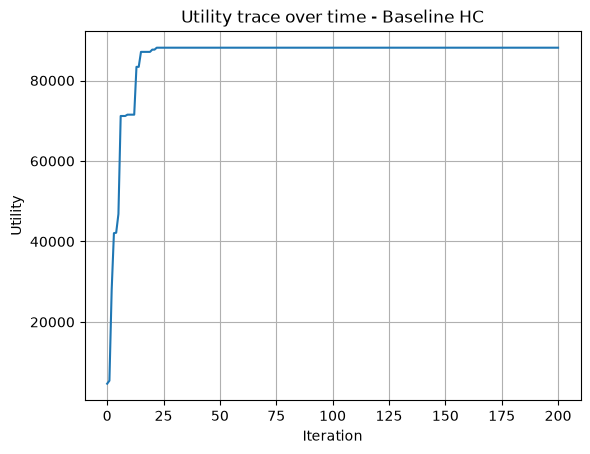

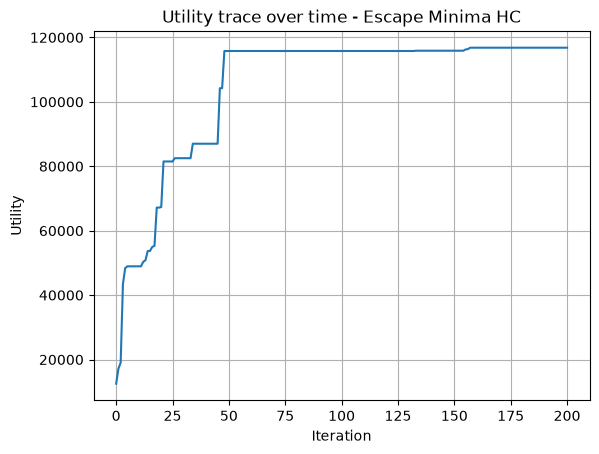

In [524]:
import matplotlib
import matplotlib.pyplot as plt
%matplotlib inline

np.random.seed(42)

traces_base = [hill_climb_base(workload_28, 200)[2] for _ in range(1000)]
traces_minim = [hill_climb_escape_minima(workload_28, 200)[2] for _ in range(1000)]

plt.plot(traces_base[0])
plt.xlabel("Iteration")
plt.ylabel("Utility")
plt.title("Utility trace over time - Baseline HC")
plt.grid(True)
plt.show()

plt.plot(traces_minim[0])
plt.xlabel("Iteration")
plt.ylabel("Utility")
plt.title("Utility trace over time - Escape Minima HC")
plt.grid(True)
plt.show()

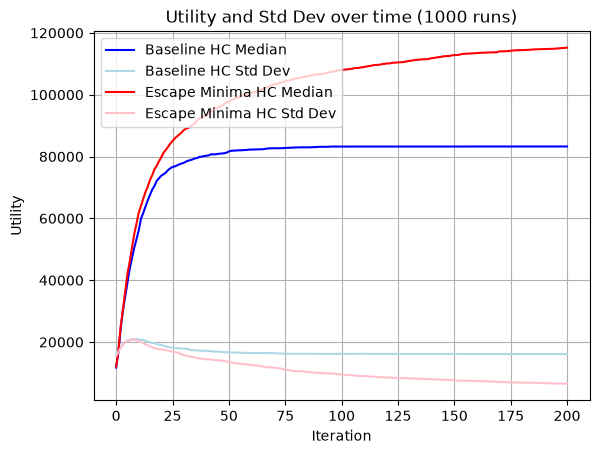

In [525]:
%matplotlib inline

base_median = np.median(traces_base, axis=0)
minim_median = np.median(traces_minim, axis=0)

base_std = np.std(traces_base, axis=0)
minim_std = np.std(traces_minim, axis=0)


plt.plot(base_median, color="blue", label="Baseline HC Median")
plt.plot(base_std, color="lightblue", label="Baseline HC Std Dev")

plt.plot(minim_median, color="red", label="Escape Minima HC Median")
plt.plot(minim_std, color="pink", label="Escape Minima HC Std Dev")



plt.xlabel("Iteration")
plt.ylabel("Utility")
plt.title("Utility and Std Dev over time (1000 runs)")
plt.legend(loc='upper left')
plt.grid(True)
plt.show()

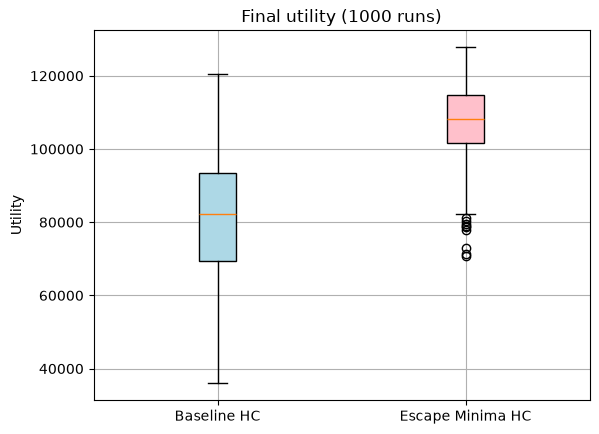

In [526]:

%matplotlib inline

np.random.seed(42)


best_base = [hill_climb_base(workload_28, 100)[1][1] for _ in range(1000)]
best_minim = [hill_climb_escape_minima(workload_28, 100)[1][1] for _ in range(1000)]

bplot = plt.boxplot([best_base, best_minim], patch_artist=True, tick_labels=['Baseline HC', 'Escape Minima HC'])
for patch, colour in zip(bplot["boxes"], ["lightblue", "pink"]):
    patch.set_facecolor(colour)

plt.title("Final utility (1000 runs)")
plt.ylabel("Utility")
plt.grid(True)
plt.show()

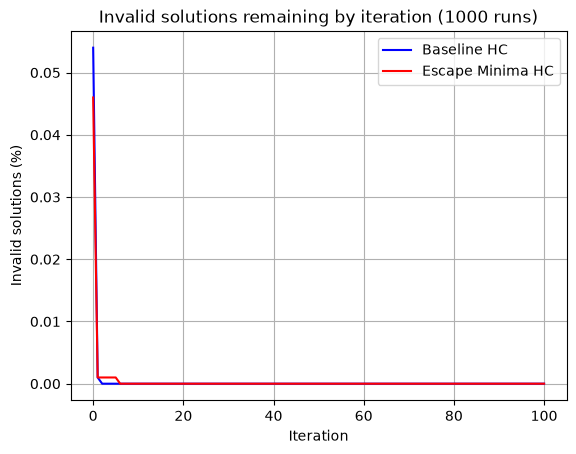

In [527]:
%matplotlib inline

np.random.seed(42)

traces_base = [hill_climb_base(workload_28, 100)[2] for _ in range(1000)]
traces_minim = [hill_climb_escape_minima(workload_28, 100)[2] for _ in range(1000)]

def percent_invalid_at(i, traces):
    return sum([trace[i] == 0 for trace in traces]) / len(traces)

base_invalid_sols = [percent_invalid_at(i, traces_base) for i in range(len(traces_base[0]))]
minim_invalid_sols = [percent_invalid_at(i, traces_minim) for i in range(len(traces_minim[0]))]

plt.plot(base_invalid_sols, color="blue", label="Baseline HC")
plt.plot(minim_invalid_sols, color="red", label="Escape Minima HC")

plt.xlabel("Iteration")
plt.ylabel("Invalid solutions (%)")
plt.title("Invalid solutions remaining by iteration (1000 runs)")
plt.legend(loc='upper right')
plt.grid(True)
plt.show()

# Part 2: Advanced Metaheuristic Engineering

In [528]:
workload_90 = load_workload_instance("multi_resource_n90_m5.txt")
print(f"n = {workload_90[0]}")
print(f"m = {workload_90[1]}")
print(f"Utilities shape = {workload_90[2].shape}")
print(f"Demands shape = {workload_90[3].shape}")
print(f"Capacities shape = {workload_90[4].shape}")

n = 90
m = 5
Utilities shape = (90,)
Demands shape = (5, 90)
Capacities shape = (5,)


# Part 3: Empirical Study and Hypothesis Testing